**Aim:** Preprocessing scRNA-seq datasets

**Tools**: 
- [`scanpy`](https://scanpy.readthedocs.io/en/stable/)
    - https://scanpy-tutorials.readthedocs.io/en/latest/pbmc3k.html#Preprocessing
        - Identify highly-variable genes
Tasks:
- [X] Load `adata` objects and merge them into one big dataset
- [X] Identify "dead cells"!
- [x] Data cleaning
    - Initially, we have seen we need to find more dead cells!
    - Run Scrublet with `batch_key='batch'` option. 
    

In [ ]:
import os, sys
import pickle
import numpy as np 
import pandas as pd
from glob import glob
import anndata as ad
import scanpy as sc
import scanpy.external as sce
import scez 

import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages

/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Global seed set to 0
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/flax/struct.py:132: FutureWarning: jax.tree_util.register_keypaths is deprecated, and will be removed in a future release. Please use `register_pytree_with_keys()` instead.
  jax.tree_util.register_keypaths(data_clz, keypaths)
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/flax/struct.py:132: FutureWarning: jax.tree_util.register_keypaths is deprecated, and will be removed in a future release. Please use `register_pytree_with_keys()` instead.
  jax.tree_util.register_keypaths(data_clz, keypaths)


In [ ]:
from utils import *

In [ ]:
# mkdir -pv figures

### Load `cellranger` results and label samples

<!-- https://www.kallistobus.tools/tutorials/kb_aggregate/python/kb_aggregating_count_matrices.html -->



In [ ]:
%%time 
data = {}
for file in sorted(glob('counts/*/outs/filtered_feature_bc_matrix.h5')):
    sample = file.split('/')[1].replace('-','')
    print (sample, file)
    
    adata = sc.read_10x_h5(file)#, gex_only=False)
    
    data[sample] = adata
    del adata
    print ('_'*50)


In [ ]:
!mkdir -pv preprocessing

In [ ]:
name = 'preprocessing/adatas-raw.pkl'

save_obj(data, name)

In [ ]:
ls -s --block-size=M preprocessing/adatas-raw.pkl

___


In [48]:
name = 'preprocessing/adatas-raw.pkl'
data = load_obj(name)

In [49]:
new_keys = [
    'MDMA_male_1',
    'MDMA_acute_female_1',
    'MDMA_acute_female_2',
    'MDMA_acute_female_3',
    'MDMA_acute_male_1',
    'MDMA_acute_male_2',
    'MDMA_acute_male_3',

    'MDMA_male_2',
    'MDMA_male_3',
    
    'Meth_male_1',
    'Meth_male_2',
    'Meth_male_3',
    
    'Saline_male_1',
    'Saline_male_2',
    'Saline_male_3'
]

In [50]:
def rename(d, new_keys):
    """
    https://stackoverflow.com/questions/16475384/rename-a-dictionary-key
    """
    new_dict = {}
    for key, new_key in zip(d.keys(), new_keys):
        new_dict[new_key] = d[key]
        print(f'{new_key} <- {key}')
        
    return new_dict

In [51]:
data = rename(data,new_keys)

MDMA_male_1 <- MDMAMale
MDMA_acute_female_1 <- MDMA_acute_female_011221
MDMA_acute_female_2 <- MDMA_acute_female_100121
MDMA_acute_female_3 <- MDMA_acute_female_180921
MDMA_acute_male_1 <- MDMA_acute_male
MDMA_acute_male_2 <- MDMA_acute_male_021221_1
MDMA_acute_male_3 <- MDMA_acute_male_021221_2
MDMA_male_2 <- MDMA_male_093021
MDMA_male_3 <- MDMA_male_100121
Meth_male_1 <- Meth
Meth_male_2 <- Meth_093021
Meth_male_3 <- Meth_100121
Saline_male_1 <- SalineMale
Saline_male_2 <- Saline_093021
Saline_male_3 <- Saline_202110


### Merge datasets

In [52]:
EXPs = []
OBSs = []
for sample in data:
    
    print (sample)
    exp = data[sample].copy()
    exp.obs['batch'] = sample
    EXPs.append(exp.to_df())
    OBSs.append(exp.obs)
    
    # del exp 

MDMA_male_1
MDMA_acute_female_1
MDMA_acute_female_2
MDMA_acute_female_3


/data_gilbert/home/aarab/anaconda3/envs/sc-analysis/lib/python3.10/site-packages/anndata/_core/anndata.py:1830: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/data_gilbert/home/aarab/anaconda3/envs/sc-analysis/lib/python3.10/site-packages/anndata/_core/anndata.py:1830: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/data_gilbert/home/aarab/anaconda3/envs/sc-analysis/lib/python3.10/site-packages/anndata/_core/anndata.py:1830: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


MDMA_acute_male_1


/data_gilbert/home/aarab/anaconda3/envs/sc-analysis/lib/python3.10/site-packages/anndata/_core/anndata.py:1830: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


MDMA_acute_male_2


/data_gilbert/home/aarab/anaconda3/envs/sc-analysis/lib/python3.10/site-packages/anndata/_core/anndata.py:1830: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


... (4 outputs left out)

Meth_male_2
Meth_male_3
Saline_male_1


/data_gilbert/home/aarab/anaconda3/envs/sc-analysis/lib/python3.10/site-packages/anndata/_core/anndata.py:1830: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/data_gilbert/home/aarab/anaconda3/envs/sc-analysis/lib/python3.10/site-packages/anndata/_core/anndata.py:1830: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/data_gilbert/home/aarab/anaconda3/envs/sc-analysis/lib/python3.10/site-packages/anndata/_core/anndata.py:1830: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


Saline_male_2
Saline_male_3


/data_gilbert/home/aarab/anaconda3/envs/sc-analysis/lib/python3.10/site-packages/anndata/_core/anndata.py:1830: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/data_gilbert/home/aarab/anaconda3/envs/sc-analysis/lib/python3.10/site-packages/anndata/_core/anndata.py:1830: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [53]:
adata = ad.AnnData(
    X=pd.concat(EXPs),obs=pd.concat(OBSs)
)

/data_gilbert/home/aarab/anaconda3/envs/sc-analysis/lib/python3.10/site-packages/anndata/_core/anndata.py:1828: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/data_gilbert/home/aarab/anaconda3/envs/sc-analysis/lib/python3.10/site-packages/anndata/_core/anndata.py:1830: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [54]:
adata.obs['cond'] = adata.obs['batch'].str[:-2]

In [55]:
for c in set(adata.obs['cond']): print(c)

Saline_male
MDMA_male
Meth_male
MDMA_acute_male
MDMA_acute_female


In [56]:
adata.obs['group'] = adata.obs.cond.str.split('_').str[0]

adata.obs.group = pd.Categorical(adata.obs.group)

In [60]:
# adata.obs_names_make_unique()
adata.obs.index = [f'{idx}_{btc}' for idx, btc in zip(adata.obs.index.to_list(),adata.obs.batch.to_list())]

In [62]:
results_file = 'preprocessing/adata-raw-merged-v2.h5ad.gz'
adata.write(results_file,compression='gzip')

In [5]:
!ls -s --block-size=M preprocessing/adata-raw*

131M preprocessing/adata-raw-merged.h5ad.gz
131M preprocessing/adata-raw-merged-v2.h5ad.gz


## Data cleaning

Filtering cells with high mitochondrial gene counts
- https://www.biostars.org/p/347428/
- https://github.com/theislab/scanpy/issues/639

More Filtering!
- https://nbisweden.github.io/workshop-scRNAseq/labs/compiled/scanpy/scanpy_01_qc.html
> _A standard approach is to filter cells with low amount of reads as well as genes that are present in at least a certain amount of cells. Here we will only consider cells with at least 200 detected genes and genes need to be expressed in at least 3 cells. Please note that those values are highly dependent on the library preparation method used._

I also found the `total_counts_mt` above a certain threshold useful!

### QC Evaluation

In [ ]:
results_file = 'preprocessing/adata-raw-merged-v2.h5ad.gz'
adata = ad.read_h5ad(results_file)

In [ ]:
adata

In [5]:
adata_qc = adata.copy()

In [6]:
adata_qc.var_names_make_unique()

In [7]:
# mitochondrial genes
adata_qc.var['mt'] = adata_qc.var_names.str.startswith('mt-')  # annotate the group of mitochondrial genes as 'mt'
sc.pp.calculate_qc_metrics(adata_qc, qc_vars=['mt'], percent_top=None, log1p=False, inplace=True)

##### plots

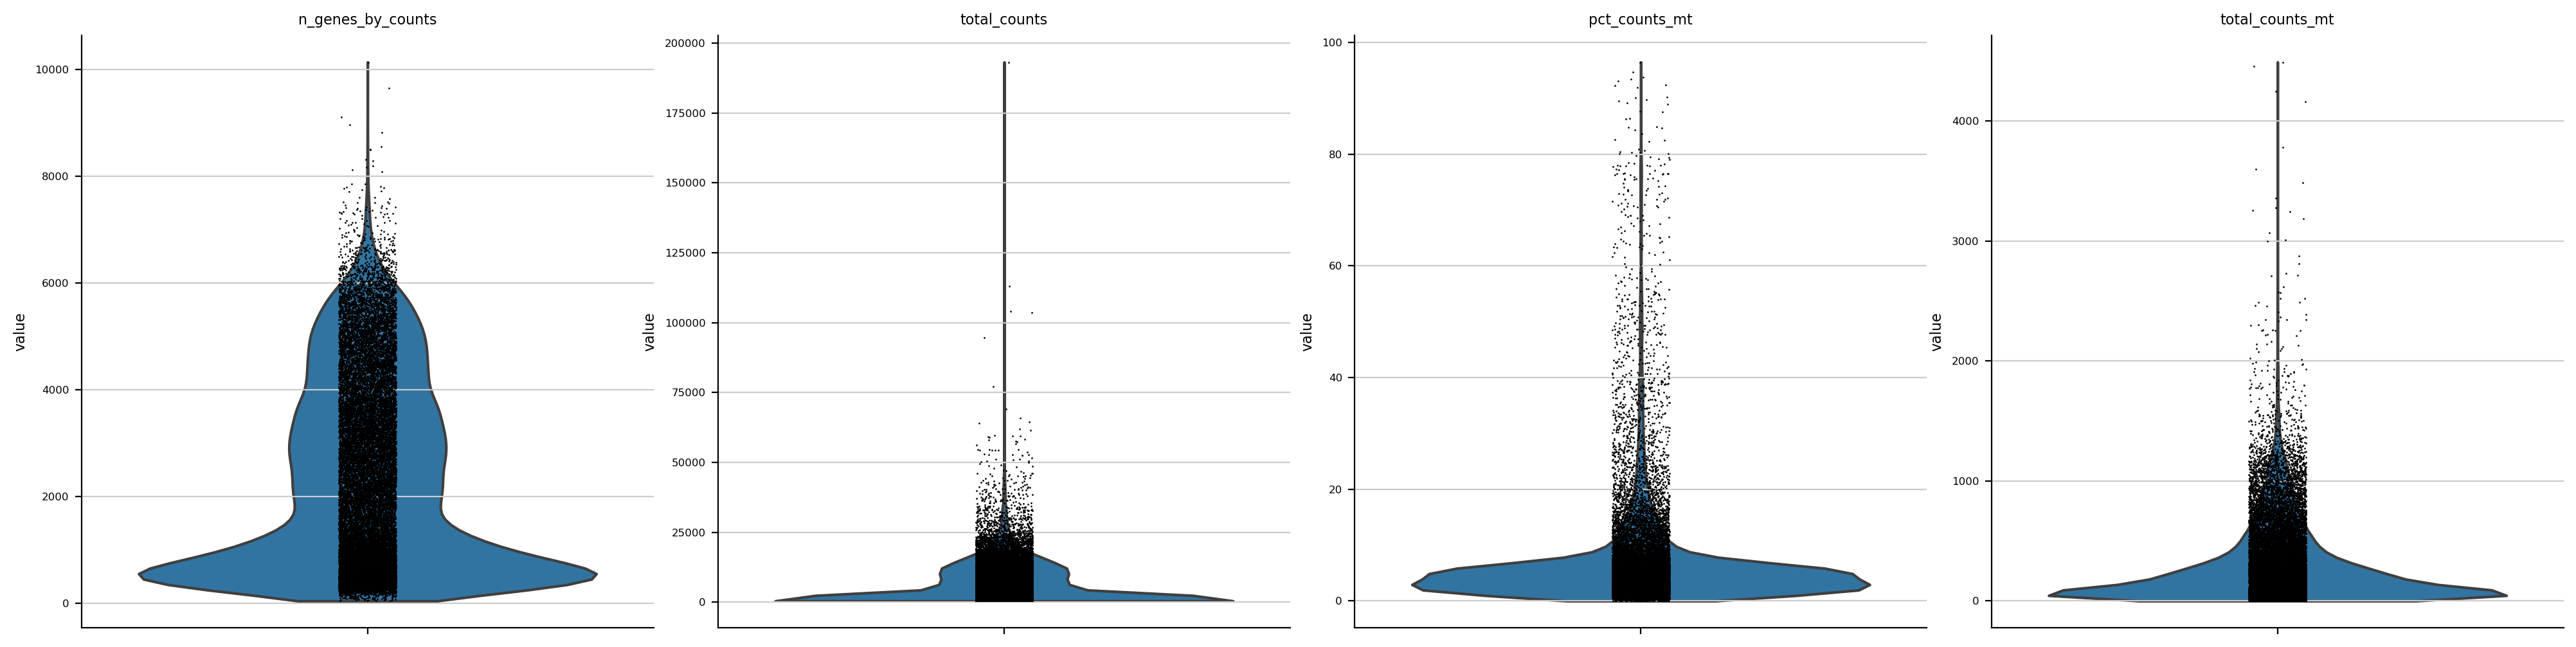

In [8]:
sc.pl.violin(adata_qc, ['n_genes_by_counts', 
                        'total_counts', 
                        'pct_counts_mt',
                        'total_counts_mt'],
             jitter=0.05, multi_panel=True)

pct_counts_mt


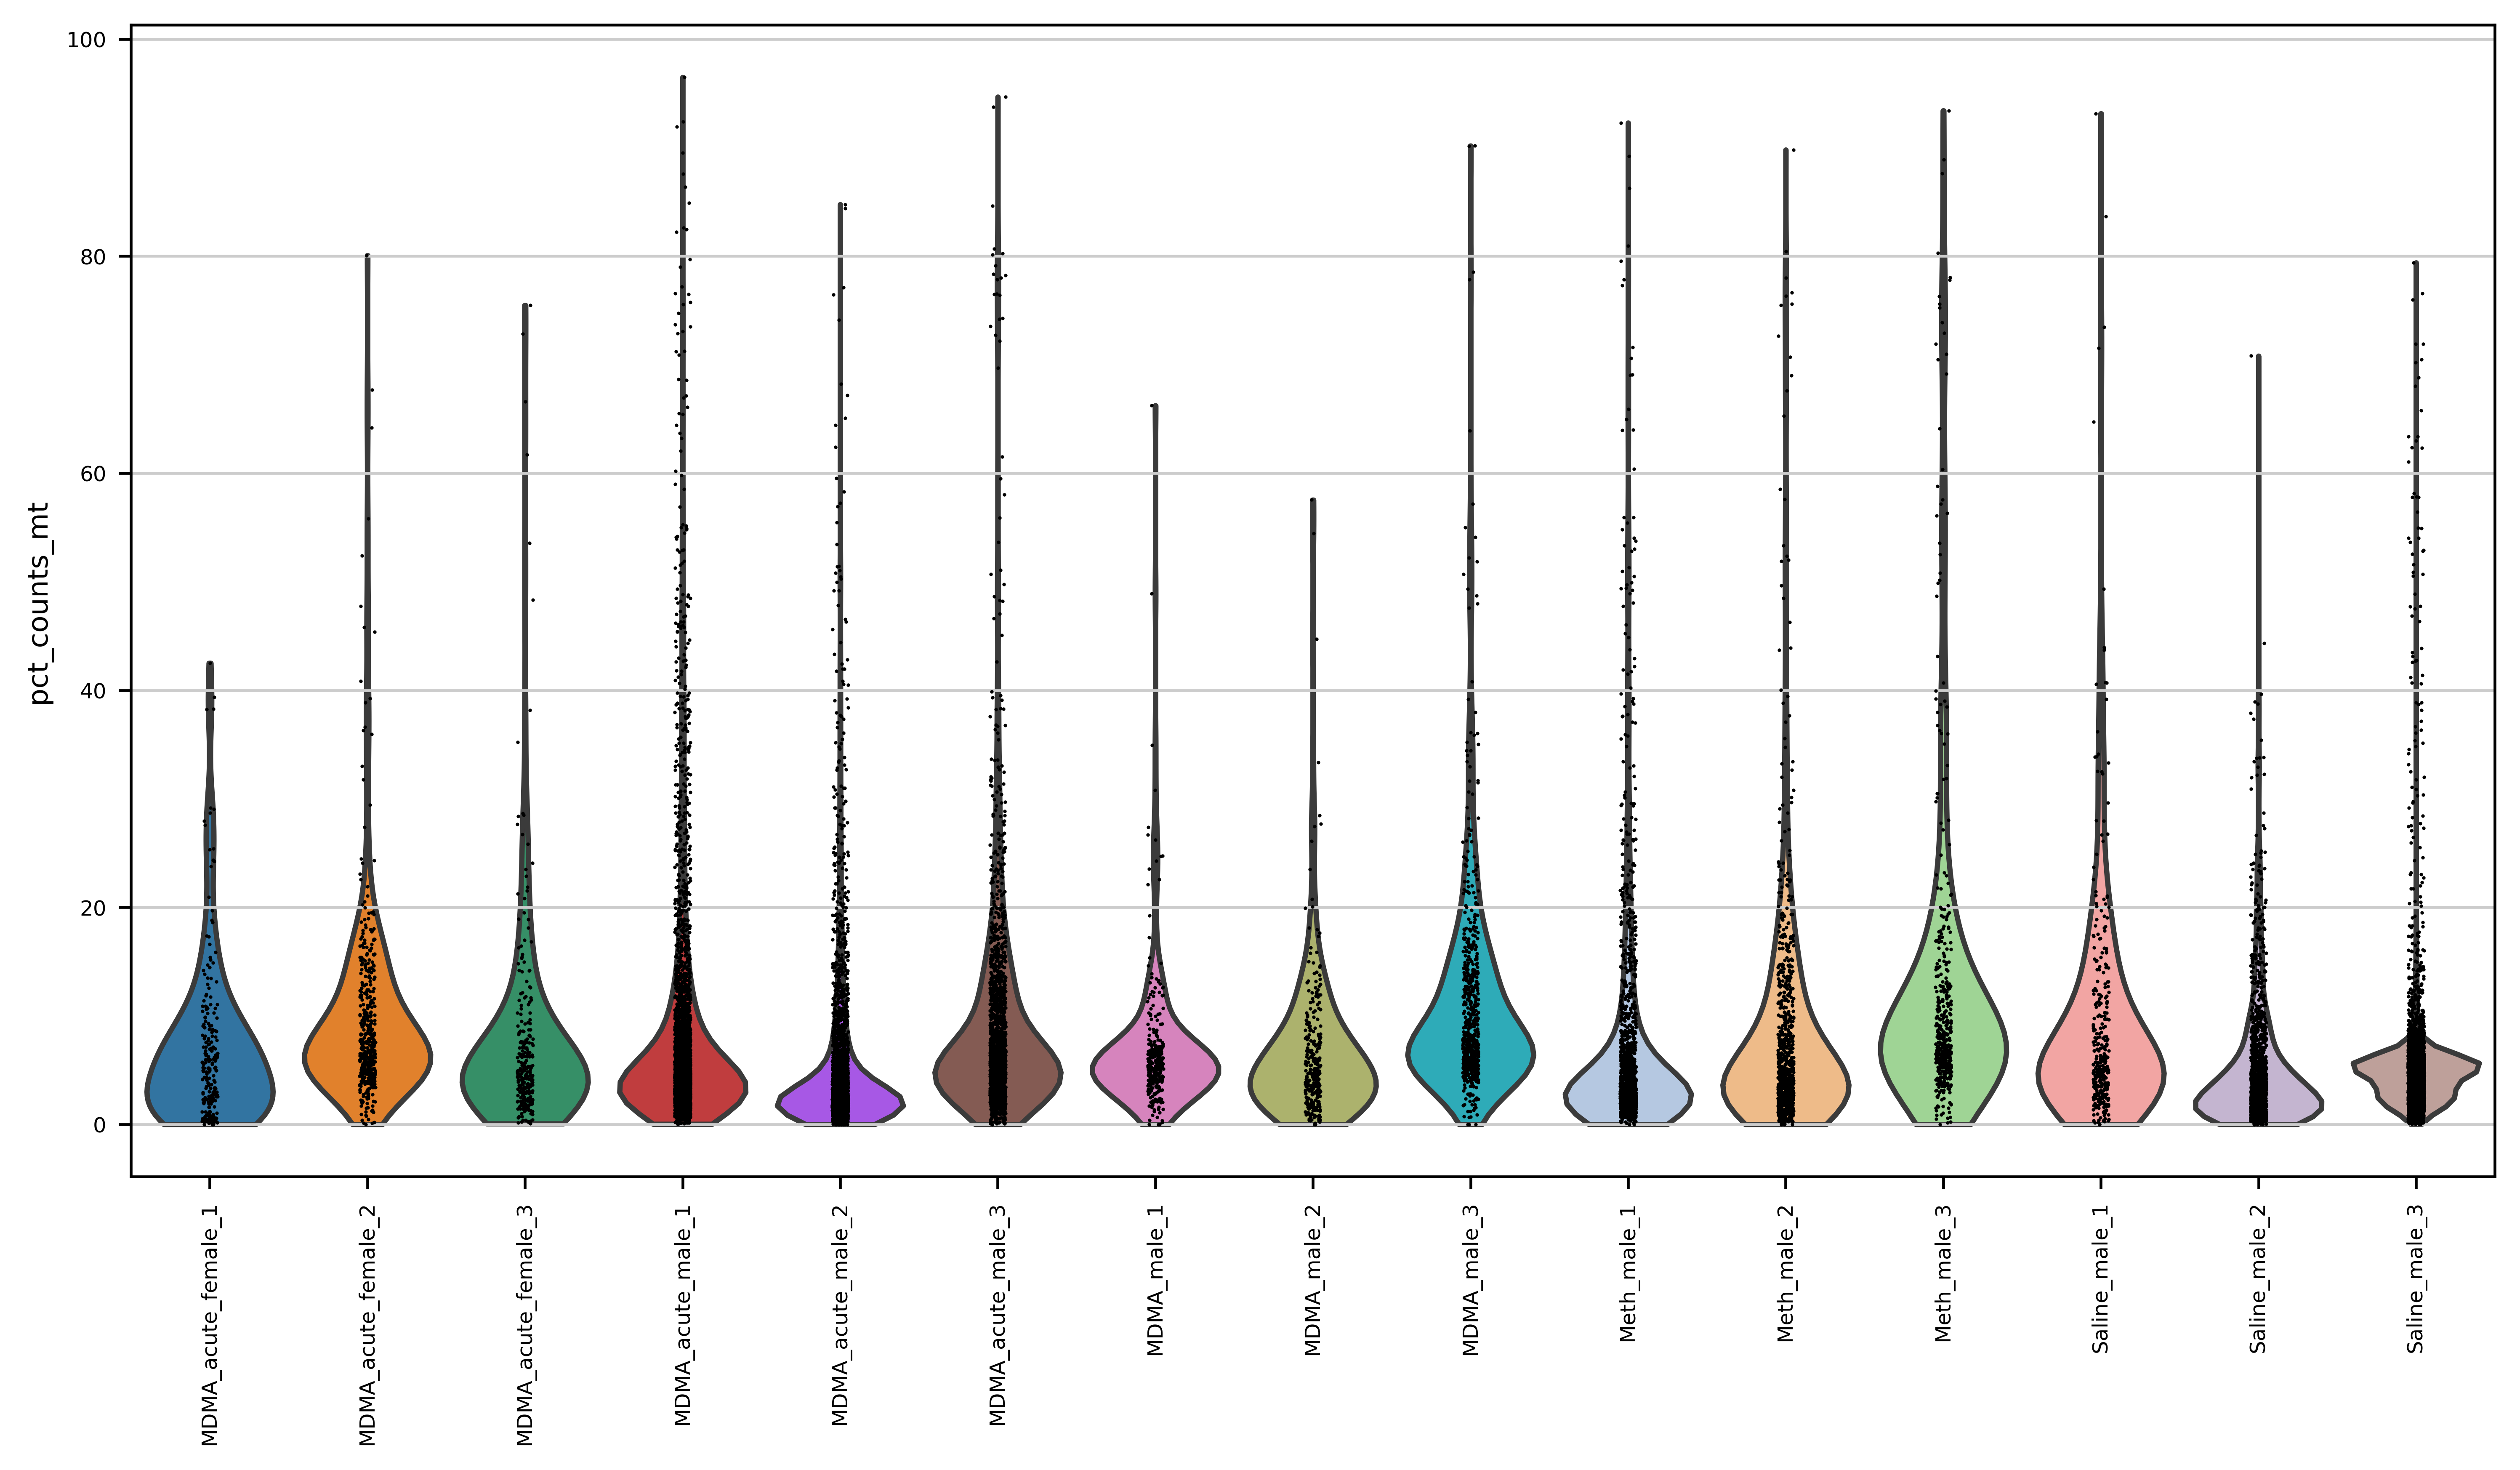

total_counts_mt


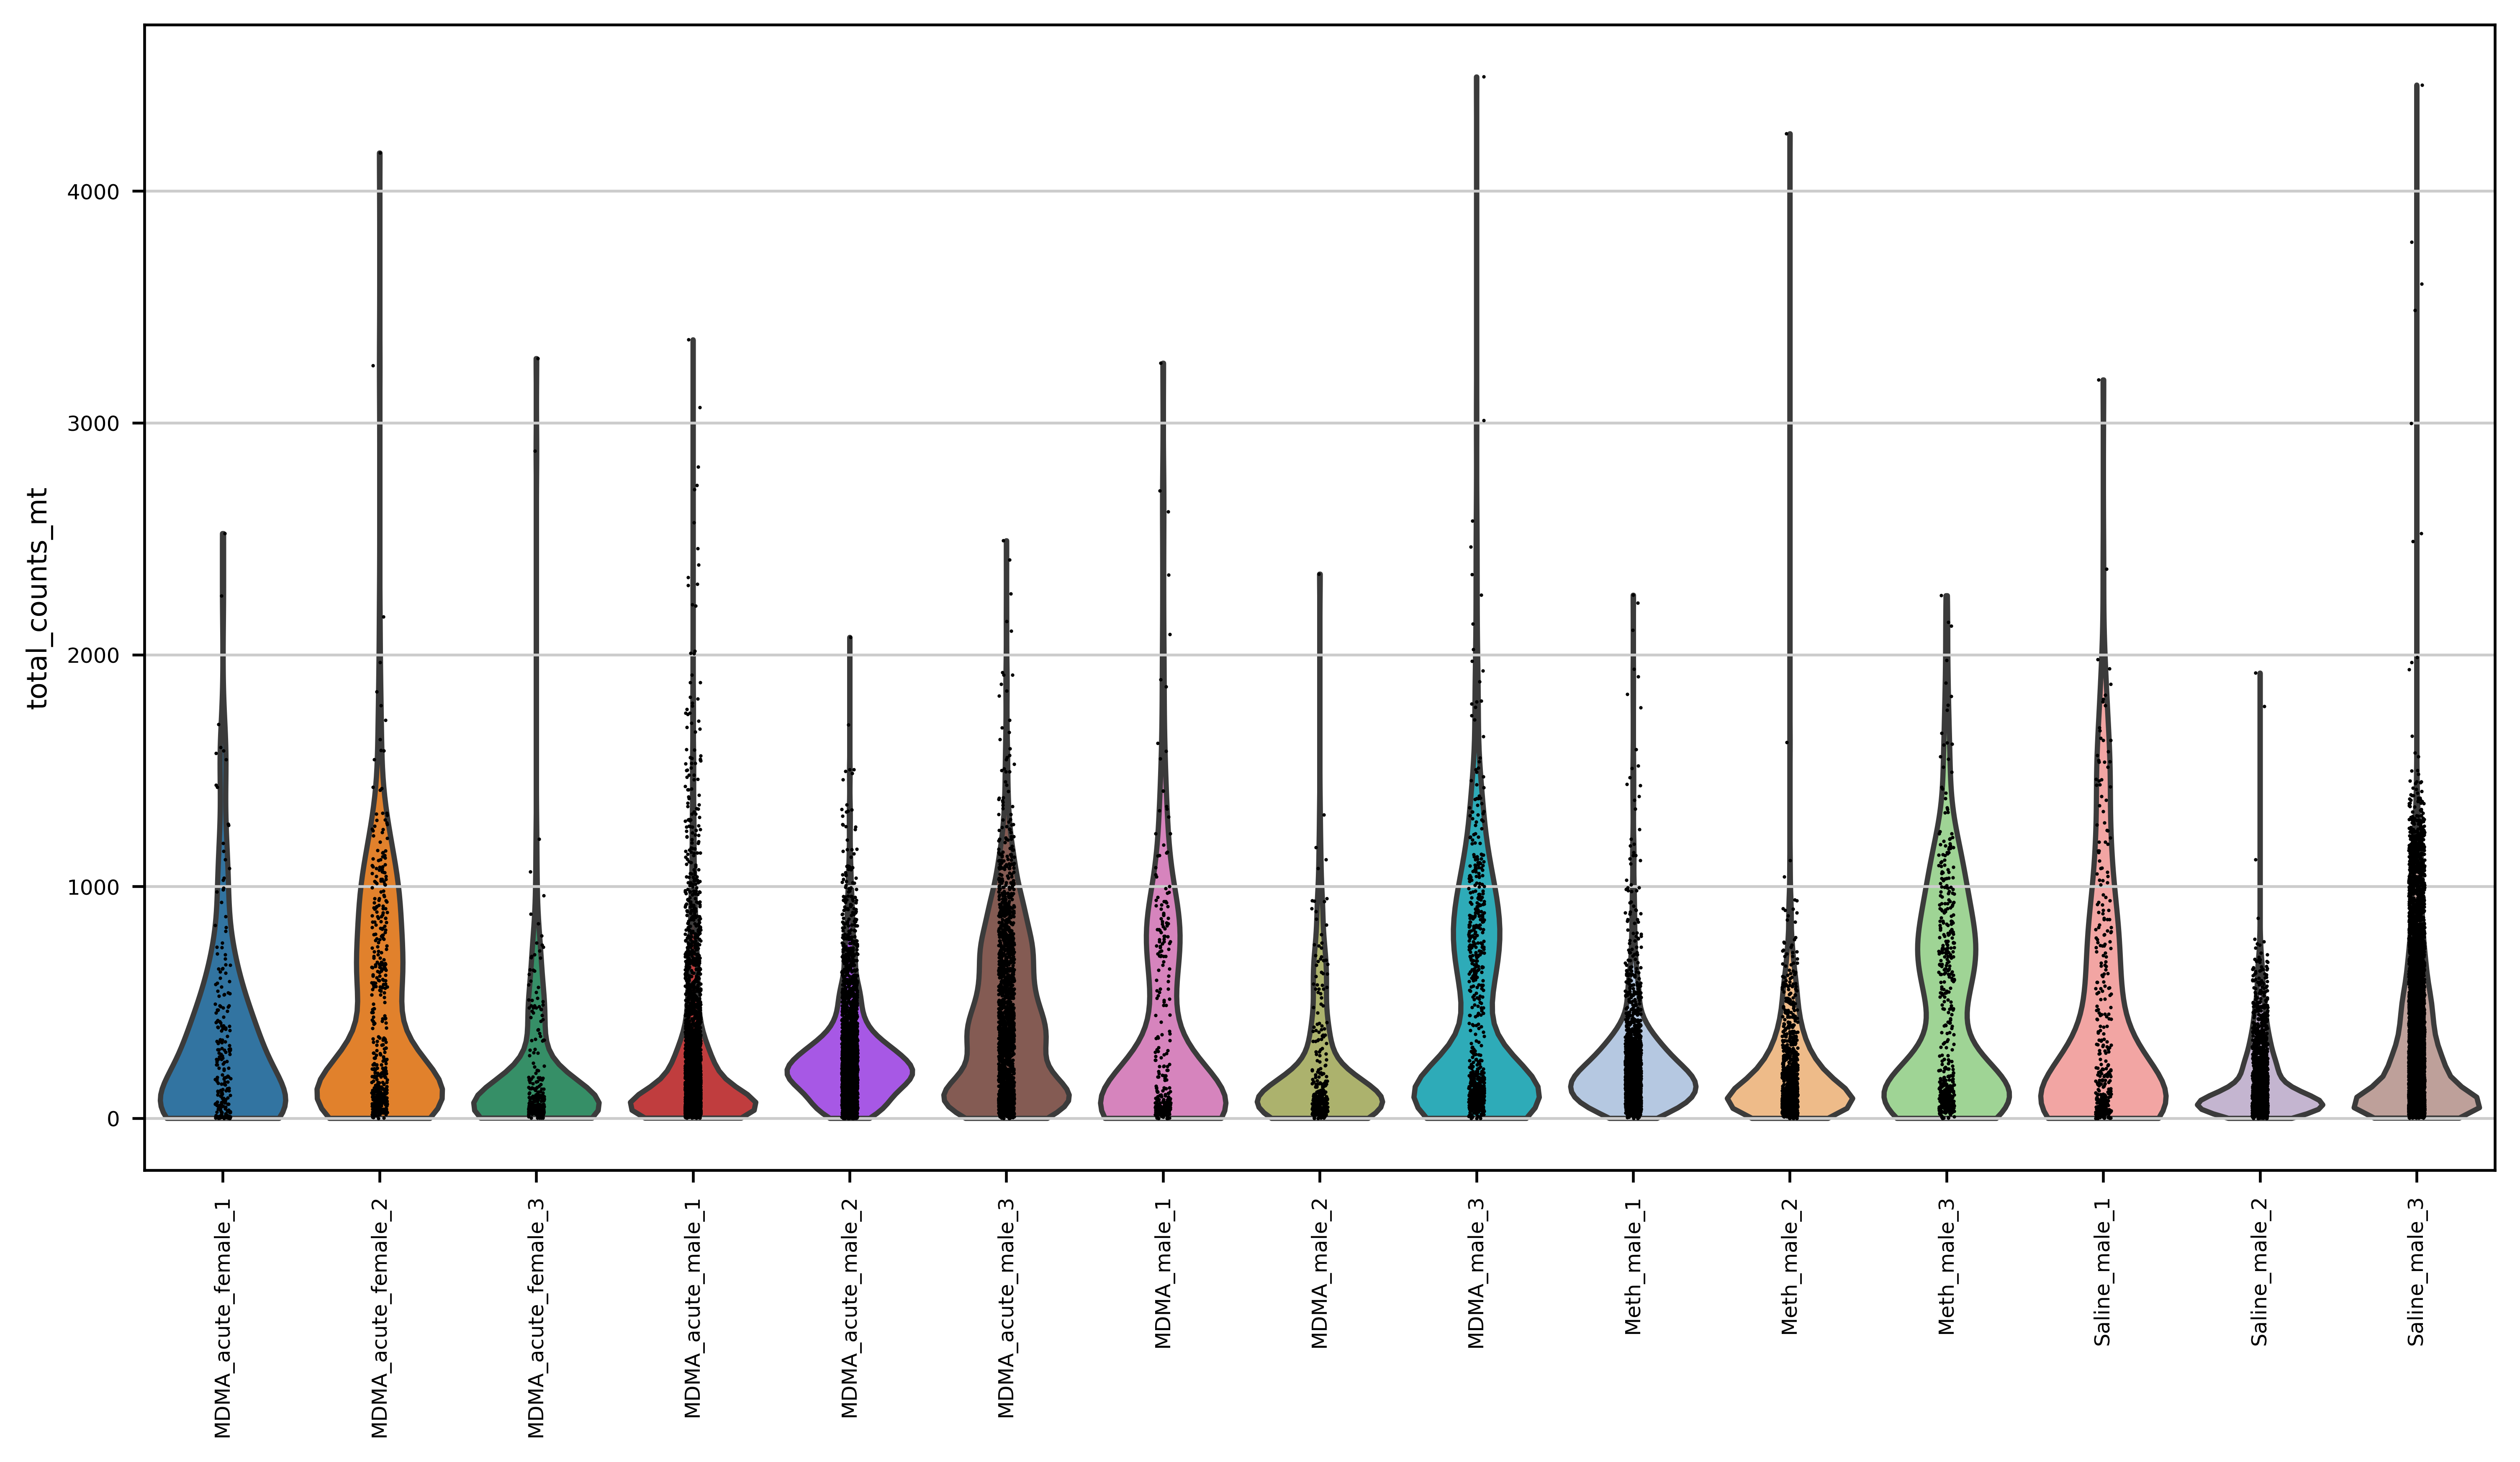

In [9]:
pdf_pages = PdfPages(f'preprocessing/violin_mitochondrial_all.pdf')
for col in [
    # 'n_genes_by_counts','total_counts',
    'pct_counts_mt','total_counts_mt'
]:
    # Create a figure instance (ie. a new page)
    fig = plt.figure(figsize=(12, 6), dpi=300)
    # Plot whatever you wish to plot
    print ('\033[1m' + col)
    ax = plt.subplot()
    sc.pl.violin(
        adata_qc, col, jitter=0.05, groupby='batch', 
        multi_panel=True, ax=ax,rotation=90
    )
    # Done with the page
    pdf_pages.savefig(fig,bbox_inches='tight')
# Write the PDF document to the disk
pdf_pages.close()

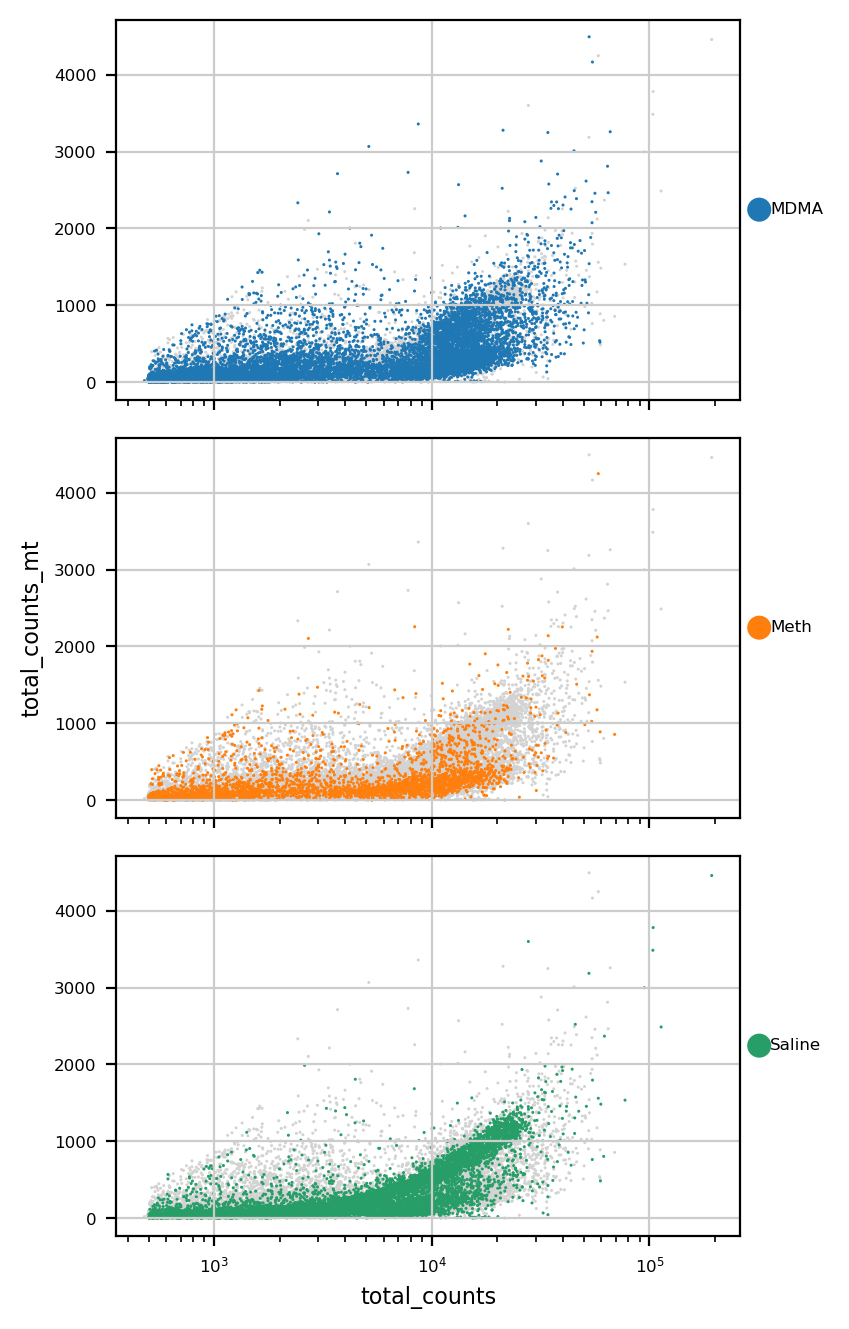

In [10]:
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(4,8), gridspec_kw={'hspace':0.1}, sharex='all')

ax1_dict = sc.pl.scatter(
    adata_qc, x='total_counts', color='group', y='total_counts_mt',ax=ax1, show=False,#alpha=0.1,
    groups=['MDMA']
)
ax1.set_title('')
ax1.set_xscale('log')
ax1.set_xlabel('')
ax1.set_ylabel('')


ax2_dict = sc.pl.scatter(
    adata_qc, x='total_counts', color='group', y='total_counts_mt',ax=ax2, show=False,#alpha=0.1,
    groups=['Meth']
    
)
ax2.set_title('')
ax2.set_xscale('log')
ax2.set_xlabel('')

ax3_dict = sc.pl.scatter(
    adata_qc, x='total_counts', color='group', y='total_counts_mt',ax=ax3, show=False,#alpha=0.1,
    groups=['Saline']
    
)
ax3.set_title('')
ax3.set_xscale('log')
ax3.set_ylabel('')
plt.savefig('preprocessing/scatter_total_counts_mt_vs_total_counts.pdf')
plt.show()

##### Prepare for UMAP

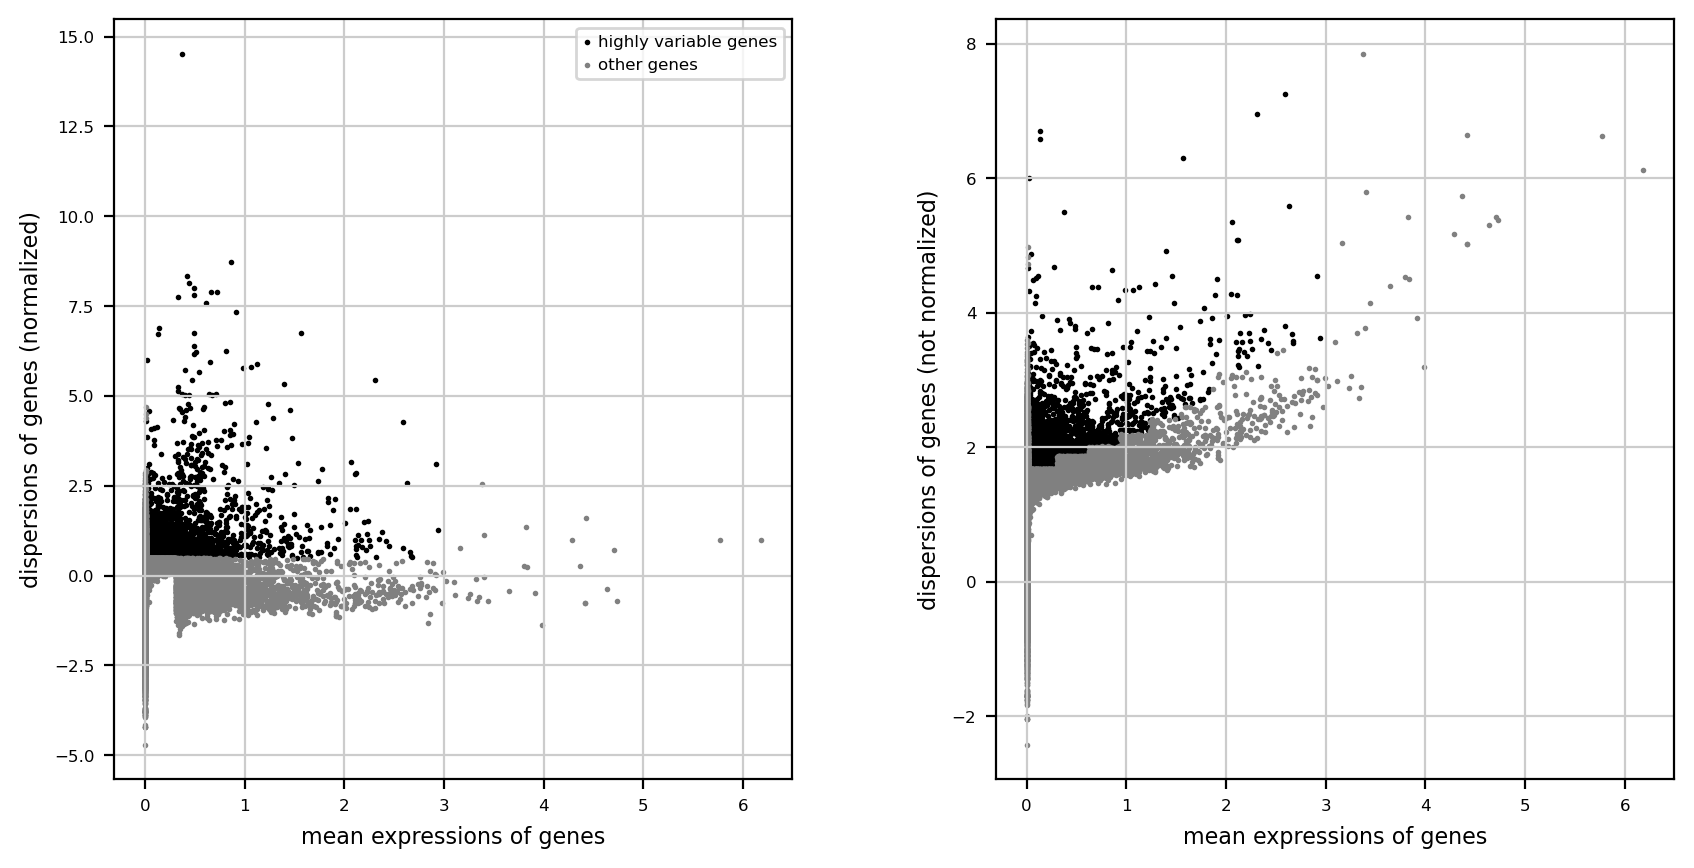

In [11]:
scez.normalization(adata_qc)
sc.pl.highly_variable_genes(adata_qc)

In [12]:
adata_qc.raw = adata_qc
adata_qc = adata_qc[:, adata_qc.var.highly_variable]

regress_out
- https://github.com/theislab/single-cell-tutorial/issues/35
- https://github.com/scverse/scanpy/issues/526#issuecomment-471488594

In [13]:
sc.pp.regress_out(adata_qc, ['total_counts', 'pct_counts_mt'])

In [14]:
sc.pp.scale(adata_qc, max_value=10)

In [15]:
adata_qc.layers["scaled"] = adata_qc.X.copy()

In [16]:
sc.pp.pca(adata_qc,n_comps=30)
sc.pp.neighbors(adata_qc)    # why can't we just work with the default neighbors?
#, use_rep=rep, n_neighbors=n_neighbor)
sc.tl.umap(adata_qc)

/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


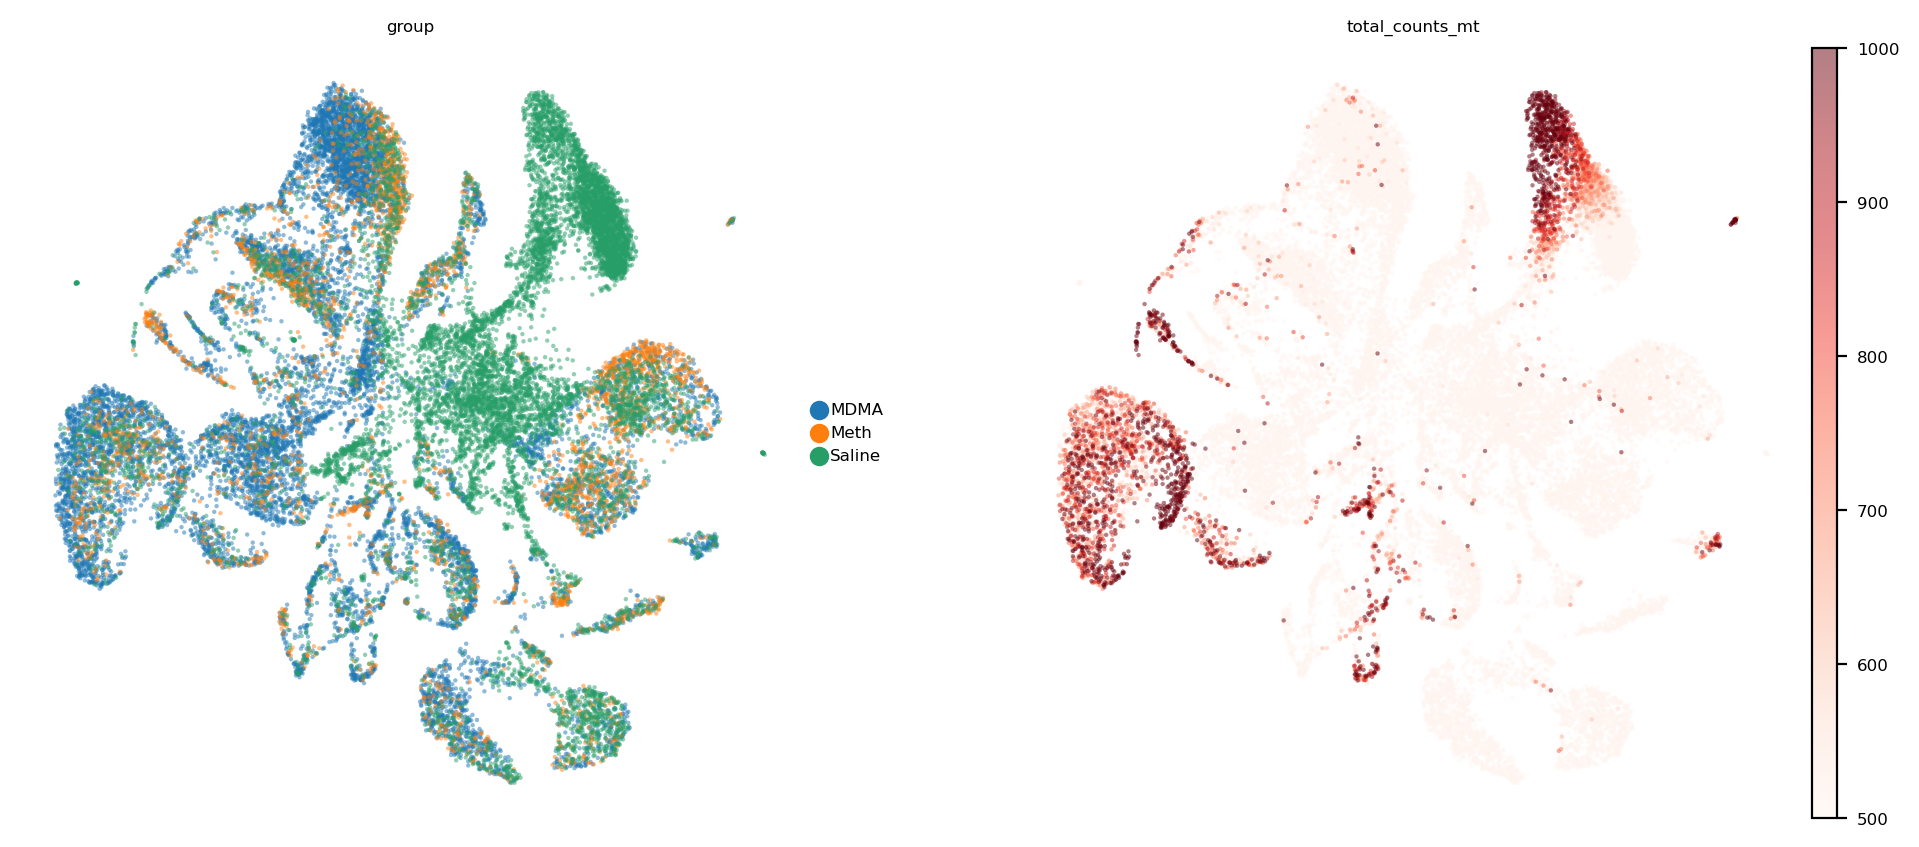

In [17]:
sc.pl.umap(
    adata_qc, 
    color=['group','total_counts_mt'],#'Snap25'],#
    # legend_fontsize='x-small',
    cmap='Reds', 
    layer='scaled',
    size=10, hspace=2,
    alpha=0.5,
    vmax=1000,
    vmin=500,
    save='all.pdf',
    # add_outline=.1
)

!mv figures/umapall.pdf preprocessing/total_counts_mt_umap.pdf

##### Save adata 

In [18]:
results_file = 'preprocessing/adata-qc-v2.h5ad.gz'
adata_qc.write(results_file,compression='gzip')

In [19]:
!ls -s --block-size=M preprocessing/adata-qc*

 976M preprocessing/adata-qc.h5ad.gz  1013M preprocessing/adata-qc-v2.h5ad.gz


### Remove doublet

- https://github.com/swolock/scrublet/blob/master/examples/scrublet_basics.ipynb

<!-- > #### Plot doublet score histograms for observed transcriptomes and simulated doublets
The simulated doublet histogram is typically bimodal. The left mode corresponds to "embedded" doublets generated by two cells with similar gene expression. The right mode corresponds to "neotypic" doublets, which are generated by cells with distinct gene expression (e.g., different cell types) and are expected to introduce more artifacts in downstream analyses. Scrublet can only detect neotypic doublets.

> To call doublets vs. singlets, we must set a threshold doublet score, ideally at the minimum between the two modes of the simulated doublet histogram. `scrub_doublets()` attempts to identify this point automatically and has done a good job in this example. However, if automatic threshold detection doesn't work well, you can adjust the threshold with the `call_doublets()` function. For example: -->

In [20]:
adata_scr = adata.copy()

/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/anndata/_core/anndata.py:1830: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [21]:
sce.pp.scrublet(adata_scr,batch_key='batch')

/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/scanpy/preprocessing/_simple.py:251: ImplicitModificationWarning: Trying to modify attribute `.var` of view, initializing view as actual.
  adata.var['n_cells'] = number
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/anndata/_core/anndata.py:1830: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/anndata/_core/anndata.py:1830: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/scanpy/preprocessing/_normalization.py:170: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


Automatically set threshold at doublet score = 0.21
Detected doublet rate = 1.2%
Estimated detectable doublet fraction = 14.8%
Overall doublet rate:
	Expected   = 5.0%
	Estimated  = 8.2%


/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/scanpy/preprocessing/_simple.py:251: ImplicitModificationWarning: Trying to modify attribute `.var` of view, initializing view as actual.
  adata.var['n_cells'] = number
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/anndata/_core/anndata.py:1830: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/anndata/_core/anndata.py:1830: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/anndata/_core/anndata.py:1830: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_dupl

Automatically set threshold at doublet score = 0.26
Detected doublet rate = 0.0%
Estimated detectable doublet fraction = 3.3%
Overall doublet rate:
	Expected   = 5.0%
	Estimated  = 0.0%


/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/scanpy/preprocessing/_simple.py:251: ImplicitModificationWarning: Trying to modify attribute `.var` of view, initializing view as actual.
  adata.var['n_cells'] = number
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/anndata/_core/anndata.py:1830: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/anndata/_core/anndata.py:1830: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/anndata/_core/anndata.py:1830: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_dupl

Automatically set threshold at doublet score = 0.23
Detected doublet rate = 0.3%
Estimated detectable doublet fraction = 3.9%
Overall doublet rate:
	Expected   = 5.0%
	Estimated  = 8.7%


... (20 outputs left out)

/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/scanpy/preprocessing/_simple.py:251: ImplicitModificationWarning: Trying to modify attribute `.var` of view, initializing view as actual.
  adata.var['n_cells'] = number
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/anndata/_core/anndata.py:1830: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/anndata/_core/anndata.py:1830: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/anndata/_core/anndata.py:1830: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_dupl

Automatically set threshold at doublet score = 0.26
Detected doublet rate = 1.0%
Estimated detectable doublet fraction = 34.0%
Overall doublet rate:
	Expected   = 5.0%
	Estimated  = 3.0%


/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/scanpy/preprocessing/_simple.py:251: ImplicitModificationWarning: Trying to modify attribute `.var` of view, initializing view as actual.
  adata.var['n_cells'] = number
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/anndata/_core/anndata.py:1830: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/anndata/_core/anndata.py:1830: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/anndata/_core/anndata.py:1830: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_dupl

Automatically set threshold at doublet score = 0.59
Detected doublet rate = 0.1%
Estimated detectable doublet fraction = 3.6%
Overall doublet rate:
	Expected   = 5.0%
	Estimated  = 2.0%


In [22]:
scr_thr = []
for k in adata_scr.uns['scrublet']['batches']:
    scr_thr.append((k,adata_scr.uns['scrublet']['batches'][k]['threshold']))

In [23]:
adata_scr.obs.groupby(['group','predicted_doublet']).size()

group   predicted_doublet
MDMA    False                11248
        True                    52
Meth    False                 3228
        True                    21
Saline  False                10244
        True                    23
dtype: int64

In [24]:
results_file = 'preprocessing/adata-scr.h5ad.gz'
adata_scr.write(results_file,compression='gzip')

In [25]:
!ls -s --block-size=M $results_file

243M preprocessing/adata-scr.h5ad.gz


### Filtering

In [26]:
adata1 = adata.copy()

/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/anndata/_core/anndata.py:1830: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [27]:
adata1

AnnData object with n_obs × n_vars = 24816 × 32285
    obs: 'batch', 'cond', 'group'

In [28]:
adata1.layers["counts"] = adata1.X.copy()

#### filter by `mt` QC labels 
Remove cells that have 
- [x] high mitochondrial genes expressed 
- [x] high total counts `mt`
<!-- - \[?] high total counts -->

In [29]:
thr_pct_mt = 20
thr_cnt_mt = 1000

In [30]:
# filter based on MT counts % 

filter_stat_df = pd.concat([
    adata_qc.obs.groupby('batch').size(),
    adata_qc[adata_qc.obs.pct_counts_mt > thr_pct_mt].obs.groupby('batch').size(),
    adata_qc[adata_qc.obs.total_counts_mt > thr_cnt_mt].obs.groupby('batch').size(),
    adata_qc[
        (adata_qc.obs.pct_counts_mt > thr_pct_mt) |
        (adata_qc.obs.total_counts_mt > thr_cnt_mt)
    ].obs.groupby('batch').size(),
],axis=1).rename(columns={
    0:'total number of cells',
    1:f'pct_counts_mt > {thr_pct_mt}',
    2:f'total_counts_mt > {thr_cnt_mt}',
    3:f'pct_counts_mt > {thr_pct_mt} OR total_counts_mt > {thr_cnt_mt}'
})

filter_stat_df

,total number of cells,pct_counts_mt > 20,total_counts_mt > 1000,pct_counts_mt > 20 OR total_counts_mt > 1000
batch,,,,
MDMA_acute_female_1,246,15,17,32
MDMA_acute_female_2,475,27,65,85
MDMA_acute_female_3,294,21,4,25
MDMA_acute_male_1,3706,306,129,387
MDMA_acute_male_2,3327,131,44,170
MDMA_acute_male_3,1930,146,131,268
MDMA_male_1,314,13,26,38
MDMA_male_2,305,11,5,15
MDMA_male_3,703,75,98,165


In [31]:
filter_stat_df.sum()

total number of cells                           24816
pct_counts_mt > 20                               1188
total_counts_mt > 1000                           1133
pct_counts_mt > 20 OR total_counts_mt > 1000     2208
dtype: int64

Actual filtering!

In [32]:
adata1 = adata1[~
    ((adata_qc.obs.pct_counts_mt > thr_pct_mt) | (adata_qc.obs.total_counts_mt > thr_cnt_mt))
]

In [33]:
adata1

View of AnnData object with n_obs × n_vars = 22608 × 32285
    obs: 'batch', 'cond', 'group'
    layers: 'counts'

#### Basic filtering

In [34]:
min_genes=150
min_cells=3

Actual filtering!

In [35]:
shape_before = adata1.shape
print(f'Before:\n\t{adata1.shape[0]} cells, {adata1.shape[1]} genes')
# Basic filtering:
sc.pp.filter_cells(adata1, min_genes=min_genes)
sc.pp.filter_genes(adata1, min_cells=min_cells)
shape_after = adata1.shape

print(f'After:\n\t{adata1.shape[0]} cells, {adata1.shape[1]} genes')

Before:
	22608 cells, 32285 genes


/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/scanpy/preprocessing/_simple.py:140: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs['n_genes'] = number
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/anndata/_core/anndata.py:1830: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/anndata/_core/anndata.py:1830: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


After:
	22560 cells, 22288 genes


/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scverse/lib/python3.10/site-packages/anndata/_core/anndata.py:1830: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


#### filter doublet


In [36]:
# remove doublet
doublet_cells = set(adata_scr.obs.index[adata_scr.obs.predicted_doublet])
print(
    f'from {len(doublet_cells)} doublets only {len(doublet_cells & set(adata1.obs.index))} cells are not filtered already!'
)

from 96 doublets only 82 cells are not filtered already!


Actual filtering!

In [37]:
adata1 = adata1[~adata1.obs.index.isin(list(doublet_cells & set(adata1.obs.index)))]

### Save pre-processed data 

In [38]:
adata2 = adata1.copy()

In [39]:
adata2.obs = adata2.obs[['batch','cond','group']]

del adata2.var 
del adata2.uns

In [40]:
adata2

AnnData object with n_obs × n_vars = 22478 × 22288
    obs: 'batch', 'cond', 'group'
    layers: 'counts'

In [41]:
results_file = 'preprocessing/adata-cleaned-v2.h5ad.gz'
adata2.write(results_file,compression='gzip')

    v1 Wed Aug 10 17:16:14 PDT 2022
    v2 Fri Mar 31 19:21:57 PDT 2023

In [42]:
!ls -s --block-size=M $results_file

264M preprocessing/adata-cleaned-v2.h5ad.gz


# 
<!-- Wed Apr 27 15:50:17 PDT 2022 -->

In [43]:
!date

Mon Apr  3 15:53:05 PDT 2023
